# 06-01 - Prompts and Masks

You send clicks and a box to a segment-anything model that has never seen Princeton, read the three masks it returns for one click, and segment a picture of your own.

We start with the crop of block 7 the lecture clicked on and the masks it got. Then we load the open model on your laptop, send it the same click, two clicks, a background click and a box, and score every mask against the footprint. At the end you click on a photograph.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import fm_tools as fm

plt.rcParams["figure.dpi"] = 72

scene = fm.load_scene("data/scene.json")
reference = json.load(open("data/ground_truth.json"))["p06"]
torch_ok = fm.torch_available()
ready = {name: torch_ok and fm.model_ready(name) for name in ("sam2", "clip")}
print(f"the window of {scene['window']['date']}: {scene['window']['pixels']:,} pixels a side at "
      f"{scene['window']['resolution_m']} m, {scene['blocks']['n']} blocks, "
      f"{scene['chips']['tiled']['total']:,} chips; the deep learning library is "
      f"{'ready' if torch_ok else 'missing, so the cells that need it are skipped'}; the open models are "
      f"{'ready' if all(ready.values()) else 'not loadable here, so the cells that run them are skipped'}")

the window of 2023-08-20: 10,240 pixels a side at 0.3 m, 25 blocks, 1,600 chips; the deep learning library is ready; the open models are ready


## The window and the crop

The cell reads the window at 2.4 m with its blocks, the crop of block 7 the lecture prompted, and the footprints inside it.

the crop: 1024 pixels, 307 m, 127 footprints   reference 127


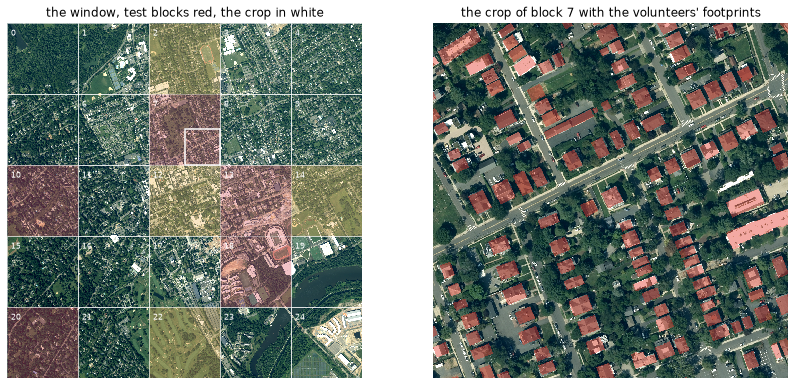

In [2]:
small, _ = fm.read_rgb("data/window_2m4.tif")
blocks = gpd.read_file("data/layers.gpkg", layer="blocks")
z = fm.read_npz("data/prompts_7.npz")
crop, footprints = fm.stretch(z["crop"]), z["footprints"]
origin, pr = scene["block"]["origin"], scene["prompt"]
mark = ((origin[0] + pr["crop_origin"][0]) // 8, (origin[1] + pr["crop_origin"][1]) // 8, pr["crop_px"] // 8)
n_foot = len(np.unique(footprints[footprints > 0]))
print(f"the crop: {pr['crop_px']} pixels, {pr['crop_px'] * 0.3:.0f} m, {n_foot} footprints"
      f"   reference {reference['everything']['footprints']}")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
fm.show_window(axes[0], small, blocks, "the window, test blocks red, the crop in white", mark=mark)
fm.show_mask(axes[1], crop, footprints > 0, "the crop of block 7 with the volunteers' footprints", alpha=0.45)

The left picture is the window of Lecture 05, three kilometres around Nassau Hall, with the five test blocks in red and the crop of block 7 outlined in white, a quarter of the residential block at the full 30 cm. The right picture is the crop with the footprints the OpenStreetMap volunteers drew. No model in this notebook has seen any of them. They are the referee, as in Precept 05, and the roofs under the trees are drawn whole as before.

## One click, three masks

The cell reads the lecture's click on one roof and the three masks the large model returned, with the model's own predicted overlap of each.

the click at [695.75, 49.23] on footprint 1878 of 1,584 pixels
predicted overlap 0.96, 0.49, 0.91; IoU with the footprint 0.78, 0.43, 0.77; the model's choice: mask 1


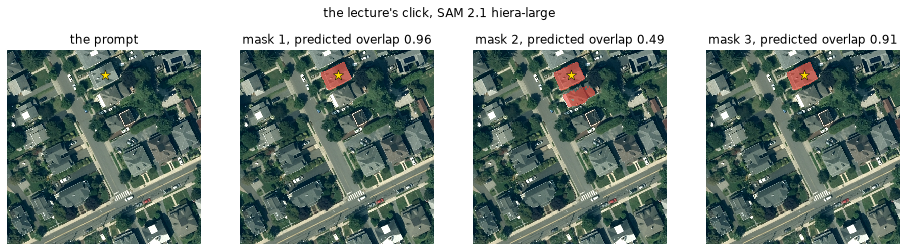

In [3]:
point, building = pr["point"], z["building_mask"] > 0
scores = z["scores_one_point"]
ious = [fm.iou(m, building) for m in z["masks_one_point"]]
print(f"the click at {point} on footprint {pr['building']} of {pr['building_px']:,} pixels")
print("predicted overlap " + ", ".join(f"{s:.2f}" for s in scores) + "; IoU with the footprint "
      + ", ".join(f"{v:.2f}" for v in ious) + f"; the model's choice: mask {int(np.argmax(scores)) + 1}")
large = scene["models"]["sam2_large"]["name"]
fig = fm.show_masks(crop, z["masks_one_point"], scores, points=[point], labels=[1],
                    suptitle=f"the lecture's click, {large}")

A click is an ambiguous prompt. The star marks one roof; the model does not know whether you mean the roof section, the whole house or the house with its yard, so it returns three masks, one per reading, each with a number that says how good it thinks the mask is. The printed line holds those numbers beside the true overlap with the footprint. Look at which mask the model trusts most and whether the footprint agrees.

## The model on your laptop

The cell loads the smallest open segment-anything model, counts its weights and runs its image encoder once over the crop.

In [4]:
if torch_ok and ready['sam2']:
    sam = fm.load_sam()
    embedded = fm.embed_image(sam, z["crop"])
    levels = embedded["embeddings"]
    shapes = ", ".join(f"{e.shape[-1]} by {e.shape[-1]} with {e.shape[1]} numbers" for e in levels)
    print(f"{scene['models']['sam2']['name']}: {fm.count_weights(sam[0]):,} weights"
          f"   reference {reference['prompt']['weights']:,}")
    print(f"the image encoder read the crop once in {embedded['seconds']:.1f} s on this processor: {shapes}")
else:
    print(fm.NO_TORCH if not torch_ok else fm.NO_MODEL)

SAM 2.1 hiera-tiny: 31,440,721 weights   reference 31,440,721
the image encoder read the crop once in 0.9 s on this processor: 256 by 256 with 32 numbers, 128 by 128 with 64 numbers, 64 by 64 with 256 numbers


The model has two halves. The heavy half, the image encoder, reads the picture once and turns it into grids of numbers, three here at three scales. The light half, the mask decoder, takes a prompt and those grids and returns a mask in a fraction of a second, so you can click as often as you like without paying for the picture again. This is the tiny member of the family, a seventh of the lecture's model, on your processor alone. Note the seconds.

## The same click, sent by you

The cell sends the lecture's click to the model on your laptop, prints its three masks beside the reference, and draws them.

your predicted overlaps 0.55, 0.44, 0.91   reference 0.55, 0.44, 0.91
IoU with the footprint 0.56, 0.59, 0.76   reference 0.56, 0.59, 0.76
the lecture's large model: 0.96, 0.49, 0.91


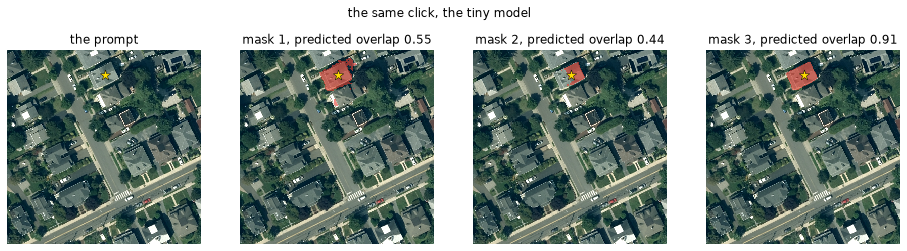

In [5]:
if torch_ok and ready['sam2']:
    masks, scores = fm.prompt(sam, embedded, points=[point], labels=[1])
    ious = [fm.iou(m, building) for m in masks]
    ref_ = reference["prompt"]["one_click"]
    mine = ", ".join(f"{s:.2f}" for s in scores)
    print(f"your predicted overlaps {mine}   reference " + ", ".join(f"{s:.2f}" for s in ref_["scores"]))
    print("IoU with the footprint " + ", ".join(f"{v:.2f}" for v in ious)
          + "   reference " + ", ".join(f"{v:.2f}" for v in ref_["iou"]))
    lecture = ", ".join(f"{s:.2f}" for s in reference["prompt"]["lecture"]["scores_one_point"])
    print(f"the lecture's large model: {lecture}")
    fig = fm.show_masks(crop, masks, scores, points=[point], labels=[1],
                        suptitle="the same click, the tiny model")
else:
    print(fm.NO_TORCH if not torch_ok else fm.NO_MODEL)

Same click, smaller model. The three masks come back in the same order of readings, and the numbers differ: the tiny model is less sure about the whole house than the large one was. Compare your line with the reference the course computed on a processor, and expect them to agree to the second decimal. Then compare both with the lecture's line. A model's confidence is its own; the IoU with the footprint is the referee's, and the two need not rank the masks the same way.

## Two clicks, a background click, a box

The cell adds a second click on the roof, then a click just outside it marked as background, then sends the footprint's box instead.

two clicks 0.89, IoU 0.74   reference 0.89
with a background click 0.71, IoU 0.74   reference 0.71
the box 0.95, IoU 0.78   reference 0.95


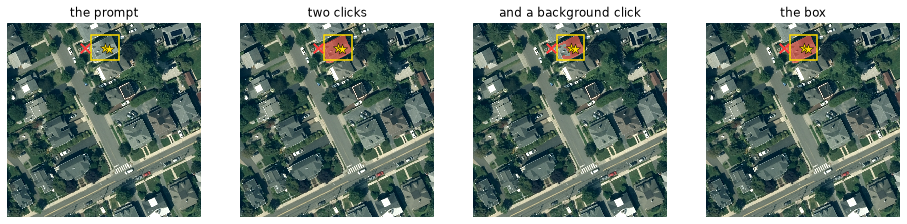

In [6]:
if torch_ok and ready['sam2']:
    p2, neg, box = pr["point2"], pr["negative"], pr["box"]
    m2, s2 = fm.prompt(sam, embedded, points=[point, p2], labels=[1, 1], multimask=False)
    m3, s3 = fm.prompt(sam, embedded, points=[point, p2, neg], labels=[1, 1, 0], multimask=False)
    m4, s4 = fm.prompt(sam, embedded, box=box, multimask=False)
    rp = reference["prompt"]
    print(f"two clicks {s2[0]:.2f}, IoU {fm.iou(m2[0], building):.2f}"
          f"   reference {rp['two_clicks']['score']:.2f}")
    print(f"with a background click {s3[0]:.2f}, IoU {fm.iou(m3[0], building):.2f}"
          f"   reference {rp['background']['score']:.2f}")
    print(f"the box {s4[0]:.2f}, IoU {fm.iou(m4[0], building):.2f}   reference {rp['box']['score']:.2f}")
    fig = fm.show_masks(crop, [m2[0], m3[0], m4[0]], [s2[0], s3[0], s4[0]], points=[point, p2, neg],
                        labels=[1, 1, 0], box=box, titles=["two clicks", "and a background click", "the box"])
else:
    print(fm.NO_TORCH if not torch_ok else fm.NO_MODEL)

More prompt, less ambiguity. With two clicks on the roof the model returns one mask and no readings; a cross marks a click that says this pixel is not the object, which trims the mask; a box is the strongest prompt of the three, because it fixes the extent. The IoU with the footprint moves with each. The box follows the roof's edge as the picture shows it, the footprint follows the wall as the volunteers drew it, and the gap between the two is the eave.

## Everything, no classes

The cell reads the everything masks the lecture computed on the crop, counts how many footprints they cover at an overlap of one half, and draws them.

171 masks from a grid of clicks   reference 171
79 of 127 footprints are covered by a mask at an overlap of one half, 48 are not   reference 79 of 127


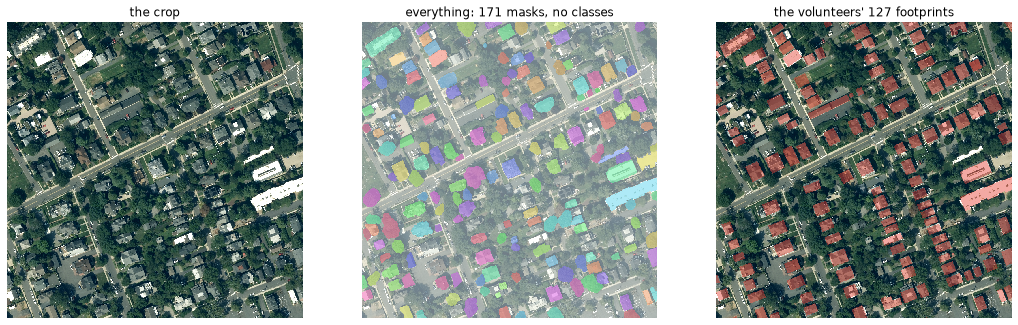

In [7]:
every = z["everything"]
best, covered, missed = fm.coverage(every, footprints, threshold=0.5)
re_ = reference["everything"]
print(f"{int(every.max())} masks from a grid of clicks   reference {re_['masks']}")
print(f"{len(covered)} of {len(best)} footprints are covered by a mask at an overlap of one half, "
      f"{len(missed)} are not   reference {re_['covered']} of {re_['footprints']}")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fm.show_image(axes[0], crop, "the crop")
fm.show_instances(axes[1], crop, every, f"everything: {int(every.max())} masks, no classes")
fm.show_mask(axes[2], crop, footprints > 0, f"the volunteers' {len(best)} footprints", alpha=0.45)

The everything mode is a grid of clicks, 32 by 32 here, each answered with three masks, the masks kept when the model trusts them and the duplicates dropped. What comes out is a tiling of the crop into objects without a name: a roof, a tree crown, a driveway, a lawn, all equal. It took the large model seconds on a graphics chip and takes a laptop minutes, so the kit ships it. The footprints covered say what a label machine could save.

## Your own image

The cell takes the first picture in `my_images`, or the kit's photograph of the class flight when the folder is empty, clicks once, and writes the mask beside the notebook.

photo_site.jpg: 2000 by 1500 px, read in 0.4 s; the click at (1850, 350), the roof of the building at the right edge
predicted overlaps 0.51, 0.12, 0.86; the best mask is in output/photo_site_mask.png


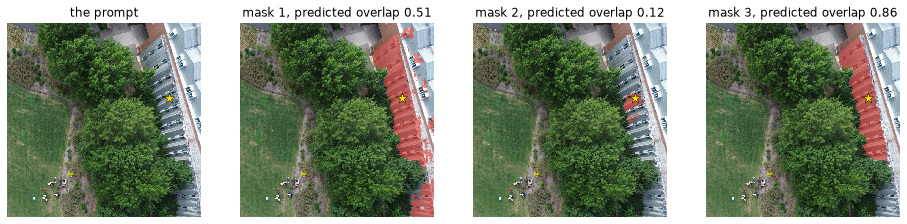

In [8]:
if torch_ok and ready['sam2']:
    path = fm.first_image("my_images", "data/photo_site.jpg")
    picture, transform, crs = fm.load_image(path)
    own, photo = path.name != "photo_site.jpg", scene["choices"]["photo"]
    click = (picture.shape[1] // 2, picture.shape[0] // 2) if own else tuple(photo["click"])
    embedded2 = fm.embed_image(sam, picture)
    masks2, scores2 = fm.prompt(sam, embedded2, points=[click], labels=[1])
    written = fm.write_mask(masks2[int(np.argmax(scores2))], f"output/{path.stem}_mask", transform, crs)
    print(f"{path.name}: {picture.shape[1]} by {picture.shape[0]} px, read in {embedded2['seconds']:.1f} s"
          f"; the click at {click}" + ("" if own else ", " + photo["what"]))
    print("predicted overlaps " + ", ".join(f"{s:.2f}" for s in scores2) + f"; the best mask is in {written}")
    fig = fm.show_masks(picture, masks2, scores2, points=[click], labels=[1], window=900)
else:
    print(fm.NO_TORCH if not torch_ok else fm.NO_MODEL)

Any JPEG, PNG or GeoTIFF you drop into the `my_images` folder goes through the same two halves: the encoder reads it once, the click returns three masks, and the best one is written next to the notebook, as a PNG for a plain picture and as GeoJSON in the picture's own map system for a GeoTIFF, which QGIS opens on top of the original. The click sits at the centre of your picture until you move it in the cell. The kit's example is a flight photograph.

## Your turn

The lecture clicked a house of ordinary size. Click the largest building that lies wholly inside the crop instead, whose footprint is three times the size, and read the three masks again. Run the cell as it is, then change the marked value and run it again.

Which of the three masks is the building now, and did the order of the model's confidence change? What does the size of the building have to do with it? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

the click at (695.75, 49.23): predicted overlaps 0.55, 0.44, 0.91; the model's choice is mask 3 with 2,088 pixels


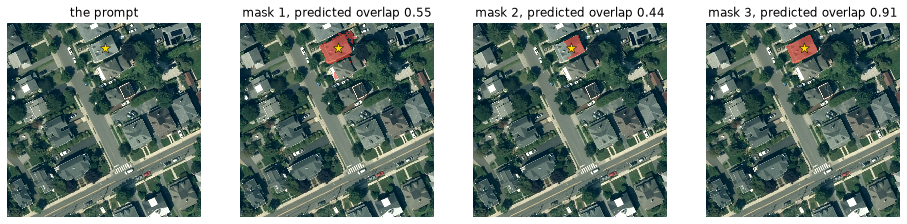

In [9]:
POINT = (695.75, 49.23)  # change me: (74.9, 68.3)
if torch_ok and ready["sam2"]:
    masks3, scores3 = fm.prompt(sam, embedded, points=[POINT], labels=[1])
    best3 = int(np.argmax(scores3))
    print(f"the click at {POINT}: predicted overlaps " + ", ".join(f"{s:.2f}" for s in scores3)
          + f"; the model's choice is mask {best3 + 1} with {int(masks3[best3].sum()):,} pixels")
    fig = fm.show_masks(crop, masks3, scores3, points=[POINT], labels=[1])
else:
    print(fm.NO_TORCH if not torch_ok else fm.NO_MODEL)

## Check your understanding

1. Why does one click return three masks and a box only one, and which is the better prompt for a building survey?
2. The model's predicted overlap and the IoU with the footprint ranked the masks differently. Which number belongs on a poster, and why?
3. The box scored below 0.8 against the footprint although it followed the roof exactly. What did the volunteers draw that the picture does not show?
4. The everything mode covered most footprints and named none. What would you still have to add to turn its masks into a building map?

## Where we are

You have sent clicks and a box to a model that has never seen Princeton, read its three readings of one click and their scores against the volunteers' footprint, seen the everything mode tile the crop into nameless objects, and segmented a picture of your own from one click. You now know what a prompt is, what a mask without a class can and cannot do, and how a model's confidence differs from a referee's score. In 06-02 a word replaces the click, and the masks are scored on the five test blocks.

## Further resources

Nothing in this course requires anything below.

- GeoAI with Python, chapter 14 on the Segment Anything models, Qiusheng Wu, 2026, https://geoai.gishub.org
- Segment Anything, Alexander Kirillov and colleagues, ICCV 2023, https://arxiv.org/abs/2304.02643
- SAM 2: Segment Anything in Images and Videos, Nikhila Ravi and colleagues, 2024, https://arxiv.org/abs/2408.00714
- The segment-geospatial package, which runs these models inside QGIS, https://samgeo.gishub.org

The masks, numbers and this kit are the course's own work, published under CC BY 4.0. The imagery is NAIP 2023 of the USDA, public domain, read from the Planetary Computer. The footprints are an OpenStreetMap extract, licensed ODbL 1.0, copyright OpenStreetMap contributors: https://www.openstreetmap.org/copyright SAM 2.1 (Meta) is released under the Apache 2.0 licence, CLIP ViT-B/16 (OpenAI) under the MIT licence. The photograph is the course's own, from the class flight of 23 September 2026, CC BY 4.0, with no person recognisable.